# 02 - Features and baseline model
**Project:** Predicting antimicrobial peptides (AMPs) from sequence with machine learning

**Goal:** I turn each peptide sequence into a set of numbers (features), train a simple baseline model on the training set, and test it on peptides from clusters it has never seen.

**Input:** `data/processed/train.csv`, `data/processed/test.csv` (from notebook 01)
**Output:** feature tables, baseline model results

In [1]:
import pandas as pd
import numpy as np

train = pd.read_csv("../data/processed/train.csv")
test = pd.read_csv("../data/processed/test.csv")

print("Train:", train.shape, "| Test:", test.shape)
print("AMPs in train:", train["label"].sum(), "| AMPs in test:", test["label"].sum())
train.head(3)


Train: (7688, 6) | Test: (1870, 6)
AMPs in train: 3840 | AMPs in test: 939


,uid,id,seq,label,length,cluster
0,s0,DRAMP29098,GLSRLFTALK,1,10,16
1,s1,DRAMP30027,EEQAKTFLDK,1,10,102
2,s2,DRAMP32992,LKKLKFLKKQ,1,10,26


## Part 2 - Build features
A model cannot read a sequence directly, so I describe each peptide with 22 numbers:
1. **Amino-acid composition (20 features):** the fraction of the peptide made up of each amino acid.
2. **Net charge:** lysine (K) and arginine (R) count as +1, aspartate (D) and glutamate (E) as -1, and histidine (H) as +0.1, a rough estimate for pH 7. Many AMPs are positively charged, which helps them bind bacterial membranes.
3. **Mean hydropathy:** the average Kyte-Doolittle score of the residues, a measure of how hydrophobic the peptide is.

I leave out sequence length, because I matched the lengths of the two classes in notebook 01 and it can no longer separate them.

In [2]:
AA = "ACDEFGHIKLMNPQRSTVWY"
KD = {"A": 1.8, "R": -4.5, "N": -3.5, "D": -3.5, "C": 2.5, "Q": -3.5, "E": -3.5,
      "G": -0.4, "H": -3.2, "I": 4.5, "L": 3.8, "K": -3.9, "M": 1.9, "F": 2.8,
      "P": -1.6, "S": -0.8, "T": -0.7, "W": -0.9, "Y": -1.3, "V": 4.2}

def featurize(seq):
    n = len(seq)
    comp = [seq.count(a) / n for a in AA]
    charge = (seq.count("K") + seq.count("R") + 0.1 * seq.count("H")
              - seq.count("D") - seq.count("E"))
    hydro = sum(KD[a] for a in seq) / n
    return comp + [charge, hydro]

cols = [f"frac_{a}" for a in AA] + ["net_charge", "mean_hydropathy"]

def make_X(df):
    return pd.DataFrame([featurize(s) for s in df["seq"]], columns=cols)

X_train, X_test = make_X(train), make_X(test)
y_train, y_test = train["label"].values, test["label"].values

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print()
print(X_train.groupby(y_train)[["net_charge", "mean_hydropathy"]].mean().round(2)
      .rename(index={0: "non-AMP", 1: "AMP"}))
X_train.head(3)

X_train: (7688, 22) | X_test: (1870, 22)

         net_charge  mean_hydropathy
non-AMP        1.47            -0.18
AMP            3.19            -0.17


,frac_A,frac_C,frac_D,frac_E,frac_F,frac_G,frac_H,frac_I,frac_K,frac_L,...,frac_P,frac_Q,frac_R,frac_S,frac_T,frac_V,frac_W,frac_Y,net_charge,mean_hydropathy
0,0.1,0.0,0.0,0.0,0.1,0.1,0.0,0.0,0.1,0.3,...,0.0,0.0,0.1,0.1,0.1,0.0,0.0,0.0,2.0,0.57
1,0.1,0.0,0.1,0.2,0.1,0.0,0.0,0.0,0.2,0.1,...,0.0,0.1,0.0,0.0,0.1,0.0,0.0,0.0,-1.0,-1.41
2,0.0,0.0,0.0,0.0,0.1,0.0,0.0,0.0,0.5,0.3,...,0.0,0.1,0.0,0.0,0.0,0.0,0.0,0.0,5.0,-0.88


## Part 3 - Train two baseline models
The AMPs in the training set have a much higher average net charge than the non-AMPs (3.19 vs 1.47), so the features carry real signal. Mean hydropathy is almost the same in both classes (-0.17 vs -0.18), so it will not help much on its own.

I train two simple models on the 7688 training peptides:
1. **Logistic regression** on standardised features, a simple model that is easy to interpret.
2. **Random forest** with 300 trees, which can capture more complex patterns.

I score both on the 1870 test peptides, which come from clusters the models have never seen. Besides accuracy, I report precision, recall, F1, ROC AUC and the Matthews correlation coefficient (MCC), which stays reliable if the classes are not perfectly balanced.

In [3]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, matthews_corrcoef)

models = {
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Random forest": RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
}

rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    rows.append({
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred),
        "recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC AUC": roc_auc_score(y_test, prob),
        "MCC": matthews_corrcoef(y_test, pred),
    })

results = pd.DataFrame(rows).set_index("model").round(3)
results

,accuracy,precision,recall,F1,ROC AUC,MCC
model,,,,,,
Logistic regression,0.789,0.786,0.796,0.791,0.859,0.578
Random forest,0.865,0.889,0.835,0.861,0.938,0.731


## Part 4 - Results and which features matter
On the test peptides, the random forest clearly beats logistic regression: ROC AUC 0.938 vs 0.859, and MCC 0.731 vs 0.578. This means the difference between AMPs and non-AMPs is not only linear, and the forest uses combinations of amino-acid fractions that a straight-line model cannot. The forest is also more precise (0.889) than it is sensitive (0.835): it misses some AMPs, but when it calls a peptide an AMP it is usually right.

These scores are my baseline. The test set contains only clusters the models never saw, so they are a fairer estimate than a random split would give. I looked at the test set once, and I did not tune anything on it.

Here I plot the ROC curves of both models and the 10 features the random forest relies on most, and I save the results table to `results/baseline_results.csv`.

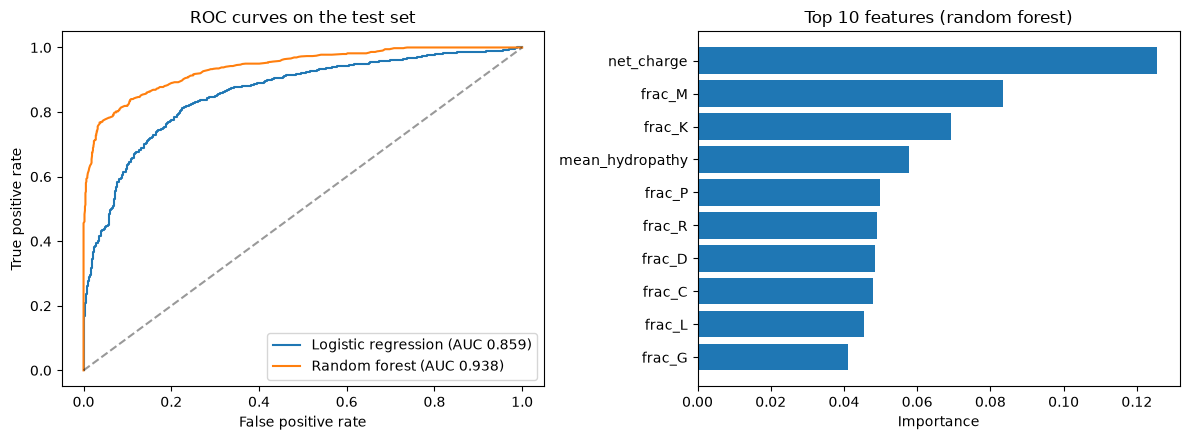

Saved: ../results/baseline_results.csv

net_charge         0.126
frac_M             0.083
frac_K             0.069
mean_hydropathy    0.058
frac_P             0.050
frac_R             0.049
frac_D             0.048
frac_C             0.048
frac_L             0.045
frac_G             0.041
dtype: float64


In [4]:
import os
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

os.makedirs("../results", exist_ok=True)
results.to_csv("../results/baseline_results.csv")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

for name, model in models.items():
    fpr, tpr, _ = roc_curve(y_test, model.predict_proba(X_test)[:, 1])
    ax[0].plot(fpr, tpr, label=f"{name} (AUC {results.loc[name, 'ROC AUC']})")
ax[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
ax[0].set_xlabel("False positive rate")
ax[0].set_ylabel("True positive rate")
ax[0].set_title("ROC curves on the test set")
ax[0].legend(loc="lower right")

rf = models["Random forest"]
imp = pd.Series(rf.feature_importances_, index=cols).sort_values().tail(10)
ax[1].barh(imp.index, imp.values)
ax[1].set_xlabel("Importance")
ax[1].set_title("Top 10 features (random forest)")

plt.tight_layout()
plt.show()

print("Saved: ../results/baseline_results.csv")
print()
print(imp.sort_values(ascending=False).round(3))


## Part 5 - Check for an N-terminal methionine bias
Net charge is the most important feature, which makes sense, and lysine (K) ranks third. But methionine (M) ranks second, and I have no biological reason to think Met itself makes a peptide antimicrobial.

A possible explanation is a database artifact. Proteins in UniProt usually start with an initiator methionine, while DRAMP lists mature peptides, where it has often been removed. If so, the model may be partly learning which database a sequence came from, not whether it is antimicrobial.

To test this, I count how many sequences in each class start with M, then remove a leading M from every sequence in both classes, rebuild the features and retrain the random forest. If the scores stay about the same, the bias is not driving my results. If they drop clearly, my baseline was inflated.

In [5]:
def make_X_seqs(seqs):
    return pd.DataFrame([featurize(s) for s in seqs], columns=cols)

def strip_m(s):
    return s[1:] if s.startswith("M") else s

for label, name in [(1, "AMPs"), (0, "non-AMPs")]:
    sub = train[train["label"] == label]
    pct = sub["seq"].str.startswith("M").mean() * 100
    print(f"{name}: {pct:.1f}% of training sequences start with M")
print()

X_train_nm = make_X_seqs(train["seq"].apply(strip_m))
X_test_nm = make_X_seqs(test["seq"].apply(strip_m))

rf_nm = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)
rf_nm.fit(X_train_nm, y_train)
pred = rf_nm.predict(X_test_nm)
prob = rf_nm.predict_proba(X_test_nm)[:, 1]

compare = pd.DataFrame({
    "with leading M": results.loc["Random forest", ["accuracy", "F1", "ROC AUC", "MCC"]],
    "leading M removed": [accuracy_score(y_test, pred), f1_score(y_test, pred),
                          roc_auc_score(y_test, prob), matthews_corrcoef(y_test, pred)],
}).round(3)
print(compare)
print()
print("Top 5 features without the leading M:")
print(pd.Series(rf_nm.feature_importances_, index=cols).sort_values(ascending=False).head(5).round(3))

AMPs: 2.0% of training sequences start with M
non-AMPs: 37.2% of training sequences start with M

          with leading M  leading M removed
accuracy           0.865              0.857
F1                 0.861              0.854
ROC AUC            0.938              0.933
MCC                0.731              0.715

Top 5 features without the leading M:
net_charge         0.130
frac_K             0.074
mean_hydropathy    0.063
frac_C             0.052
frac_R             0.051
dtype: float64


## Part 6 - Another possible shortcut: peptide length
Removing the leading M changed the scores only a little (ROC AUC 0.938 to 0.933, MCC 0.731 to 0.715), so the methionine bias was real but small. I will use the leading-M-removed scores as my cleaner baseline.

Because AMPs and non-AMPs come from different databases, other differences could also act as shortcuts. Length is the easiest to check, so I compare the length distribution of the two classes and save the M-bias comparison.

In [6]:
compare.to_csv("../results/m_bias_check.csv")

print(train.groupby("label")["seq"].apply(lambda s: s.str.len().describe().round(1)).unstack())
print()
print(pd.Series(rf_nm.feature_importances_, index=cols).filter(like="len"))

        count  mean   std   min   25%   50%   75%   max
label                                                  
0      3848.0  26.6  11.6  10.0  16.0  26.0  36.0  50.0
1      3840.0  26.6  11.4  10.0  16.0  26.0  35.0  50.0

Series([], dtype: float64)


## Part 7 - Summary of this notebook
Length is not a shortcut: AMPs and non-AMPs have the same length distribution (mean 26.6, range 10 to 50), and length was not a model feature. The only bias I found was the leading methionine, which changed ROC AUC by 0.005.

My baseline is the random forest with the leading M removed: ROC AUC 0.933, MCC 0.715 on cluster-split test peptides